2026-10-19 13:13:43,328	INFO worker.py:2033 -- Started a local Ray instance.
/usr/local/lib/python3.13/dist-packages/gymnasium/envs/registration.py:636: UserWarning: WARN: Overriding environment rllib-single-agent-env-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
2026-10-19 13:13:48,469	WARNING util.py:62 -- Install gputil for GPU system monitoring.



[+] Treinando agente de precificação dinâmica com comportamento cronológico e motoristas reais...
Iteração 01: Recompensa Média = 4734.56
Iteração 02: Recompensa Média = 4730.55
Iteração 03: Recompensa Média = 4847.60
Iteração 04: Recompensa Média = 4904.71
Iteração 05: Recompensa Média = 4927.21
Iteração 06: Recompensa Média = 5108.55
Iteração 07: Recompensa Média = 4960.76
Iteração 08: Recompensa Média = 4942.57
Iteração 09: Recompensa Média = 4973.36
Iteração 10: Recompensa Média = 5085.20
Iteração 11: Recompensa Média = 5191.57
Iteração 12: Recompensa Média = 5161.95
Iteração 13: Recompensa Média = 5311.66
Iteração 14: Recompensa Média = 5171.98
Iteração 15: Recompensa Média = 5237.26
Iteração 16: Recompensa Média = 5270.49
Iteração 17: Recompensa Média = 5228.88
Iteração 18: Recompensa Média = 5292.26
Iteração 19: Recompensa Média = 5370.15
Iteração 20: Recompensa Média = 5289.57


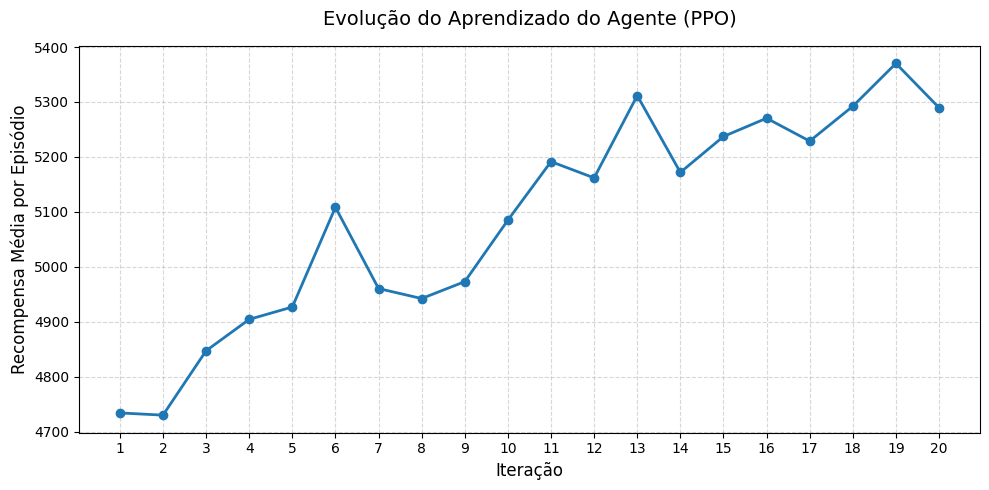


[+] Treino concluído. Testando a política aprendida em um dia completo (00h às 23h)...

Hora: 00h | Demanda Real: 23 | Motoristas: 16 | Preço Aplicado: 1.4x | Recompensa: 214.0
Hora: 01h | Demanda Real: 08 | Motoristas: 05 | Preço Aplicado: 1.4x | Recompensa: 42.0
Hora: 02h | Demanda Real: 04 | Motoristas: 03 | Preço Aplicado: 1.4x | Recompensa: 0.0
Hora: 03h | Demanda Real: 07 | Motoristas: 06 | Preço Aplicado: 1.4x | Recompensa: 28.0
Hora: 04h | Demanda Real: 09 | Motoristas: 05 | Preço Aplicado: 1.4x | Recompensa: 56.0
Hora: 05h | Demanda Real: 04 | Motoristas: 04 | Preço Aplicado: 1.4x | Recompensa: 0.0
Hora: 06h | Demanda Real: 15 | Motoristas: 22 | Preço Aplicado: 1.4x | Recompensa: 140.0
Hora: 07h | Demanda Real: 41 | Motoristas: 39 | Preço Aplicado: 1.4x | Recompensa: 504.0
Hora: 08h | Demanda Real: 44 | Motoristas: 38 | Preço Aplicado: 1.4x | Recompensa: 527.0
Hora: 09h | Demanda Real: 45 | Motoristas: 35 | Preço Aplicado: 1.4x | Recompensa: 465.0
Hora: 10h | Demanda Real: 20

In [16]:
import ray
from ray.rllib.algorithms.ppo import PPOConfig
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import torch
import matplotlib.pyplot as plt

# Inicializa o Ray de forma limpa
ray.shutdown()
ray.init(ignore_reinit_error=True)

class AmbienteTarifaDinamica(gym.Env):
    """Ambiente de precificação dinâmica para o RLlib com comportamento de demanda e motoristas realistas"""
    def __init__(self, config={}):
        super().__init__()
        self.max_motoristas = 50
        self.max_demanda = 50

        # Ação: 9 níveis de multiplicadores para flexibilidade
        self.precos_multiplicadores = [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5]
        self.espaco_acoes = spaces.Discrete(len(self.precos_multiplicadores))
        self.action_space = self.espaco_acoes

        # Estado: [demanda, motoristas, hora]
        self.espaco_observacoes = spaces.Box(low=0, high=1, shape=(3,), dtype=np.float32)
        self.observation_space = self.espaco_observacoes

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.hora = 0
        self.demanda = self._calcular_demanda_realista(self.hora)
        self.motoristas = self._calcular_motoristas_realista(self.hora)
        self.tempo = 0
        return self._obter_observacao(), {}

    def _obter_observacao(self):
        return np.array([
            self.demanda / self.max_demanda,
            self.motoristas / self.max_motoristas,
            self.hora / 24.0
        ], dtype=np.float32)

    def _calcular_demanda_realista(self, hora):
        # Simula o fluxo real de passageiros em uma cidade grande
        if 7 <= hora <= 9:
            base_demanda = np.random.randint(35, 48)  # Pico da manhã
        elif 17 <= hora <= 19:
            base_demanda = np.random.randint(38, 50)  # Pico da tarde
        elif 1 <= hora <= 5:
            base_demanda = np.random.randint(3, 10)    # Madrugada vazia
        else:
            base_demanda = np.random.randint(15, 28)   # Comercial/Normal
        return np.clip(base_demanda, 0, self.max_demanda)

    def _calcular_motoristas_realista(self, hora):
        # Simula a quantidade real de motoristas ativos dependendo do horário
        if 7 <= hora <= 9:
            base_motoristas = np.random.randint(30, 45)  # Muitos trabalhando no pico da manhã
        elif 17 <= hora <= 19:
            base_motoristas = np.random.randint(32, 47)  # Pico da tarde/noite
        elif 1 <= hora <= 5:
            base_motoristas = np.random.randint(3, 8)     # Madrugada (quase ninguém nas ruas)
        else:
            base_motoristas = np.random.randint(15, 28)    # Fluxo normal comercial
        return np.clip(base_motoristas, 1, self.max_motoristas)

    def step(self, acao):
        multiplicador = self.precos_multiplicadores[acao]
        preco_base = 10.0
        preco_final = preco_base * multiplicador

        # Queda da demanda é mais acentuada se o multiplicador for abusivo
        # Se multiplicador for 1.0 ou menor, não há perda de demanda voluntária
        perda_elasticidade = int(max(0.0, (multiplicador - 1.0) * 15))
        demanda_atendida = max(0, self.demanda - perda_elasticidade)

        corridas_realizadas = min(demanda_atendida, self.motoristas)
        receita = preco_final * corridas_realizadas

        # Penalidade por deixar clientes esperando (falta de motoristas ou cancelamentos)
        espera = max(0, demanda_atendida - self.motoristas)
        penalidade_espera = espera * 5.0

        # Penalidade por aplicar tarifa barata demais em momentos de altíssima demanda (desperdício de oportunidade)
        penalidade_subprecificacao = 0.0
        if self.demanda > 30 and multiplicador <= 1.0:
            penalidade_subprecificacao = (self.demanda - self.motoristas) * 3.0

        # Recompensa focada na receita líquida real
        recompensa = receita - penalidade_espera - penalidade_subprecificacao

        # Avança o tempo de forma estritamente ordenada
        self.hora = (self.hora + 1) % 24
        self.demanda = self._calcular_demanda_realista(self.hora)
        self.motoristas = self._calcular_motoristas_realista(self.hora)

        self.tempo += 1
        terminado = self.tempo >= 24  # Ciclo completo de um dia
        truncado = False

        return self._obter_observacao(), recompensa, terminado, truncado, {}

# 1. Configura o PPO
configuracao = (
    PPOConfig()
    .environment(AmbienteTarifaDinamica)
    .framework("torch")
    .env_runners(num_env_runners=0)
    .resources(num_gpus=0)
    .training(
        train_batch_size=1000,
        minibatch_size=100,
        num_epochs=2,
        lr=3e-4
    )
)

algoritmo = configuracao.build_algo()
historico_recompensas = []

# 2. Executa o treinamento do agente
print("\n[+] Treinando agente de precificação dinâmica com comportamento cronológico e motoristas reais...")
for iteracao in range(20):
    resultado = algoritmo.train()

    historico_metricas = resultado.get("env_runners", {})
    recompensa_media = historico_metricas.get("episode_return_mean", 0.0)

    if np.isnan(recompensa_media) or recompensa_media == 0.0:
        recompensa_media = historico_metricas.get("episode_reward_mean", 0.0)
    if np.isnan(recompensa_media) or recompensa_media == 0.0:
        recompensa_media = resultado.get("episode_reward_mean", 0.0)
    if np.isnan(recompensa_media):
        recompensa_media = 0.0

    historico_recompensas.append(recompensa_media)
    print(f"Iteração {iteracao+1:02d}: Recompensa Média = {recompensa_media:.2f}")

# Gera o gráfico de evolução do aprendizado
plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), historico_recompensas, marker='o', linestyle='-', color='#1f77b4', linewidth=2)
plt.title('Evolução do Aprendizado do Agente (PPO)', fontsize=14, pad=15)
plt.xlabel('Iteração', fontsize=12)
plt.ylabel('Recompensa Média por Episódio', fontsize=12)
plt.xticks(range(1, 21))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("\n[+] Treino concluído. Testando a política aprendida em um dia completo (00h às 23h)...\n")

# 3. Obtém o modelo RLModule para inferência
modulo_politica = algoritmo.get_module()

ambiente_teste = AmbienteTarifaDinamica()
observacao, _ = ambiente_teste.reset()
ambiente_teste.hora = 0  # Garante início à meia-noite no teste

for passo in range(24):
    tensor_observacao = torch.from_numpy(np.expand_dims(observacao, axis=0)).float()

    with torch.no_grad():
        entrada_modelo = {"obs": tensor_observacao}
        saida_modelo = modulo_politica.forward_inference(entrada_modelo)
        logits_acoes = saida_modelo["action_dist_inputs"]
        acao_escolhida = torch.argmax(logits_acoes, dim=-1).item()

    # Salva os estados atuais antes do step para o print correto
    hora_atual = ambiente_teste.hora
    demanda_atual = ambiente_teste.demanda
    motoristas_atuais = ambiente_teste.motoristas

    observacao, recompensa, terminado, truncado, _ = ambiente_teste.step(acao_escolhida)

    print(f"Hora: {hora_atual:02d}h | Demanda Real: {demanda_atual:02d} | "
          f"Motoristas: {motoristas_atuais:02d} | "
          f"Preço Aplicado: {ambiente_teste.precos_multiplicadores[acao_escolhida]}x | Recompensa: {recompensa:.1f}")

    if terminado or truncado:
        break

# Finaliza a execução do Ray
ray.shutdown()